# River Water Level & Flow Rate Station Retrieval

This notebook retrieves the full list of **water level (水位)** and **flow rate (流量)** observation stations from the
[MLIT Hydrological and Water Quality Database](http://www1.river.go.jp/), extracts their geographic coordinates,
and visualizes them on a Cartopy map.

### Workflow
1. **Search** — Query the database search endpoint for all `水位流量` stations (`KOMOKU=02`).
2. **Extract station IDs** — Parse JavaScript links in the results table.
3. **Fetch coordinates** — For each station, load its detail page and extract latitude/longitude from the map link.
4. **Map** — Plot all stations on a Cartopy map using the project's `MappingConfig` styling.

### Core Dependencies
- **Selenium** + **BeautifulSoup** — Needed because the site blocks direct HTTP requests.
- **Cartopy** + **GeoPandas** — For geographic visualization.
- **Pandas** — Data handling.

In [2]:
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path
project_root = Path(os.getcwd()).resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import re
import time
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By

from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

MappingConfig.apply_global_plot_styles()

## 1. Helper Functions

### Selenium Driver
The MLIT site blocks plain HTTP requests (`requests`, `curl`), so Selenium with headless Chrome is required.

### Coordinate Conversion
Station coordinates are encoded in the detail-page map link as DMS (Degrees-Minutes-Seconds) integers:
- `SIDO` → Latitude  (format: `DDDMMSS000`)
- `SKEIDO` → Longitude (format: `DDDMMSS000`)

For example, `SIDO=0344833000` → 34° 48′ 33.000″ N → **34.80917°**

In [3]:
def create_driver():
    """Initialize a headless Chrome Selenium driver."""
    options = webdriver.ChromeOptions()
    options.add_argument('--headless')
    options.add_argument('--no-sandbox')
    options.add_argument('--disable-dev-shm-usage')
    return webdriver.Chrome(options=options)


def dms_str_to_dd(dms_str):
    """
    Convert a DMS-encoded string (e.g. '0344833000') to decimal degrees.
    The format is DDDMMSS + fractional part (3 digits).
    """
    dms_str = dms_str.zfill(10)
    deg = int(dms_str[:3])
    min_ = int(dms_str[3:5])
    sec = float(dms_str[5:7] + '.' + dms_str[7:])
    return deg + (min_ / 60.0) + (sec / 3600.0)

## 2. Retrieve All Station IDs

The MLIT search endpoint `/cgi-bin/SrchSite.exe` accepts the following parameters:
- `KOMOKU` — Observation item code. `02` = Water Level & Flow Rate (水位流量).
- `SUIKEI` — River system filter. `0` = All.
- `KEN` — Prefecture filter. `0` = All.

Submitting the search form with no station name returns **all** registered stations.
Station IDs are embedded in JavaScript links: `JavaScript:SiteDetail1('303051283310020')`.

In [4]:
def get_all_station_ids(driver, komoku='02'):
    """
    Retrieve all station IDs for a given observation item code.
    
    Args:
        driver: Selenium WebDriver instance.
        komoku: Observation item code ('02' = Water Level & Flow Rate).
    
    Returns:
        list of dicts with keys: station_id, item, river_system, river_name, station_name, location.
    """
    url = f'http://www1.river.go.jp/cgi-bin/SrchSite.exe?KOMOKU={komoku}&SUIKEI=0&KEN=0'
    driver.get(url)
    time.sleep(2)
    
    # Click the search button to list all stations
    btn = driver.find_element(By.XPATH, "//input[@name='SUBMIT1' and @type='submit']")
    btn.click()
    time.sleep(3)
    
    soup = BeautifulSoup(driver.page_source, 'html.parser')
    
    # Find the data table (the one with header row: No, 項目, 水系名, ...)
    data_table = None
    for table in soup.find_all('table'):
        rows = table.find_all('tr')
        if len(rows) > 2:
            first_cells = [c.get_text(strip=True) for c in rows[0].find_all('td')]
            if 'No' in first_cells and '項目' in first_cells:
                data_table = table
                break
    
    if data_table is None:
        print('Warning: Could not find the data table.')
        return []
    
    stations = []
    rows = data_table.find_all('tr')[1:]  # Skip header
    for row in rows:
        cells = row.find_all('td')
        if len(cells) < 6:
            continue
        
        # Extract station ID from the JavaScript link in the station name cell
        link = row.find('a', href=re.compile(r"SiteDetail1"))
        if link:
            match = re.search(r"'(\d+)'", link.get('href'))
            if match:
                stations.append({
                    'station_id': match.group(1),
                    'item': cells[1].get_text(strip=True),
                    'river_system': cells[2].get_text(strip=True),
                    'river_name': cells[3].get_text(strip=True),
                    'station_name': cells[4].get_text(strip=True),
                    'location': cells[5].get_text(strip=True),
                })
    
    print(f'Found {len(stations)} stations for KOMOKU={komoku}')
    return stations

## 3. Extract Station Coordinates

For each station ID, the detail page at `/cgi-bin/SiteInfo.exe?ID={station_id}` contains
a link to a map viewer. The URL of this link encodes the latitude and longitude:

```
/cgi-bin/DspMapPosition.exe?...&SIDO=0344833000&SKEIDO=1350417000
```

We parse `SIDO` (latitude) and `SKEIDO` (longitude) and convert from DMS to decimal degrees.

> **Note:** This step requires one HTTP request per station. For ~2000+ stations,
> this can take 30–60 minutes. The results are cached to a CSV file so subsequent
> runs can skip the scraping.

In [19]:
def get_all_station_ids(driver, komoku='02', max_pages=None):
    """
    Retrieve all station IDs for a given observation item code by paginating.
    
    Args:
        driver: Selenium WebDriver instance.
        komoku: Observation item code ('02' = Water Level & Flow Rate).
        max_pages: Optional maximum number of pages to scrape (useful for quick testing).
    
    Returns:
        list of dicts containing station metadata.
    """
    stations = []
    page = 0
    
    while True:
        # Construct the direct pagination URL with default values matching the search form
        url = f'http://www1.river.go.jp/cgi-bin/SrchSite.exe?KOMOKU={komoku}&NAME=&SUIKEI=-00001&KASEN=&KEN=-1&CITY=&PAGE={page}'
        driver.get(url)
        time.sleep(1.5)  # Let the page load
        
        soup = BeautifulSoup(driver.page_source, 'html.parser')
        
        # Locate the results table
        data_table = None
        for table in soup.find_all('table'):
            rows = table.find_all('tr')
            if len(rows) > 2:
                first_cells = [c.get_text(strip=True) for c in rows[0].find_all('td')]
                if 'No' in first_cells and '項目' in first_cells:
                    data_table = table
                    break
        
        if data_table is None:
            print(f"No data table found on page {page}. Stopping pagination.")
            break
            
        rows = data_table.find_all('tr')[1:]  # Skip the header row
        page_stations_count = 0
        
        for row in rows:
            cells = row.find_all('td')
            if len(cells) < 6:
                continue
            
            # Extract the 15-digit station ID from the JavaScript detail function
            link = row.find('a', href=re.compile(r"SiteDetail1"))
            if link:
                match = re.search(r"'(\d+)'", link.get('href'))
                if match:
                    stations.append({
                        'station_id': match.group(1),
                        'item': cells[1].get_text(strip=True),
                        'river_system': cells[2].get_text(strip=True),
                        'river_name': cells[3].get_text(strip=True),
                        'station_name': cells[4].get_text(strip=True),
                        'location': cells[5].get_text(strip=True),
                    })
                    page_stations_count += 1
        
        # If no stations were successfully parsed on this page, stop
        if page_stations_count == 0:
            print(f"No stations parsed on page {page}. Stopping.")
            break
            
        print(f"Processed page {page} (found {page_stations_count} stations, total accumulated: {len(stations)})")
        
        # Check if the 'Next' page button exists in the HTML
        next_btn = soup.find('img', src=re.compile(r'next\.gif'))
        if not next_btn:
            print("Reached the last page (no next button found).")
            break
            
        # Optional safeguard to limit scraping during debugging
        if max_pages and page >= max_pages - 1:
            print(f"Reached max_pages limit ({max_pages}). Stopping.")
            break
            
        page += 1
        
    print(f'Total stations retrieved: {len(stations)}')
    return stations

## 4. Run the Full Retrieval Pipeline

This cell orchestrates the complete workflow:
1. Retrieve the station list.
2. For each station, fetch its coordinates.
3. Save the results to a CSV file for future reuse.

If the CSV file already exists, it is loaded directly to skip the lengthy scraping step.

In [21]:
OUTPUT_CSV = ProjectPaths.PROCESSED_DATA_DIR / 'river_water_level_stations.csv'

if OUTPUT_CSV.exists():
    print(f'Loading cached station data from {OUTPUT_CSV}')
    df_stations = pd.read_csv(OUTPUT_CSV)
    print(f'Loaded {len(df_stations)} stations.')
else:
    driver = create_driver()
    
    # Step 1: Get all station IDs
    stations = get_all_station_ids(driver, komoku='02', max_pages=5)
    
    # Step 2: Fetch coordinates for each station
    total = len(stations)
    for i, stn in enumerate(stations):
        lat, lon = get_station_coordinates(driver, stn['station_id'])
        stn['latitude'] = lat
        stn['longitude'] = lon
        if (i + 1) % 50 == 0 or (i + 1) == total:
            print(f'  Progress: {i+1}/{total} stations processed')
    
    driver.quit()
    
    # Step 3: Save to CSV
    df_stations = pd.DataFrame(stations)
    df_stations.to_csv(OUTPUT_CSV, index=False)
    print(f'Saved {len(df_stations)} stations to {OUTPUT_CSV}')

df_stations.head(10)

Processed page 0 (found 10 stations, total accumulated: 10)
Processed page 1 (found 10 stations, total accumulated: 20)
Processed page 2 (found 10 stations, total accumulated: 30)
Processed page 3 (found 10 stations, total accumulated: 40)
Processed page 4 (found 10 stations, total accumulated: 50)
Reached max_pages limit (5). Stopping.
Total stations retrieved: 50
  Progress: 50/50 stations processed
Saved 50 stations to /home/reyha/SIS_Analysis_WSL/data/processed/river_water_level_stations.csv


,station_id,item,river_system,river_name,station_name,location,latitude,longitude
0,1042110126100,水位流量,天塩川,雄信内川,下雄信内,天塩郡天塩町字雄信内市街,NaN,NaN
1,1042110300030,水位流量,石狩川,漁川,取水場,北海道恵庭市盤尻２７１,42.849444,141.501944
2,1042110624080,水位流量,鵡川,鵡川,富内,勇払郡穂別町字富内,42.781944,142.216667
3,1042110624090,水位流量,鵡川,穂別川,茂別,勇払郡穂別町字茂別,42.771944,142.146389
4,1042110724060,水位流量,沙流川,沙流川,振内,沙流郡平取町字振内,NaN,NaN
5,1042110724070,水位流量,沙流川,沙流川,荷負,沙流郡平取町字荷負,42.671944,142.183611
6,1042110931140,水位流量,釧路川,仁々志別川,北斗,釧路市北斗,43.054491,144.298555
7,1042110931910,水位流量,釧路川,釧路川,丹頂橋,釧路郡釧路町トリトウシ原野,43.041553,144.452067
8,1042129227010,水位流量,増幌川,増幌川,四線橋,北海道稚内市字増幌,45.403056,141.849722
9,1362120169010,水位流量,阿武隈川,摺上川,秋庭,福島県福島市飯坂町茂庭字秋庭,37.931944,140.423056


## 5. Data Summary

Quick overview of the retrieved dataset: total station count, coordinate coverage,
and any stations where coordinate extraction failed.

In [22]:
print(f'Total stations: {len(df_stations)}')
print(f'Stations with valid coordinates: {df_stations.dropna(subset=["latitude", "longitude"]).shape[0]}')
print(f'Stations missing coordinates: {df_stations[["latitude", "longitude"]].isna().any(axis=1).sum()}')
print()
print('Unique river systems:', df_stations['river_system'].nunique())
print()
print('Coordinate ranges:')
print(f'  Latitude:  {df_stations["latitude"].min():.4f} – {df_stations["latitude"].max():.4f}')
print(f'  Longitude: {df_stations["longitude"].min():.4f} – {df_stations["longitude"].max():.4f}')
print()
df_stations.info()

Total stations: 50
Stations with valid coordinates: 48
Stations missing coordinates: 2

Unique river systems: 12

Coordinate ranges:
  Latitude:  35.7383 – 45.4031
  Longitude: 139.0383 – 144.4521

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    50 non-null     object 
 1   item          50 non-null     object 
 2   river_system  50 non-null     object 
 3   river_name    50 non-null     object 
 4   station_name  50 non-null     object 
 5   location      50 non-null     object 
 6   latitude      48 non-null     float64
 7   longitude     48 non-null     float64
dtypes: float64(2), object(6)
memory usage: 3.2+ KB


## 6. Map All Stations with Cartopy

Visualize the geographic distribution of all retrieved water level & flow rate stations
across Japan. The map follows the project's `MappingConfig` styling conventions.

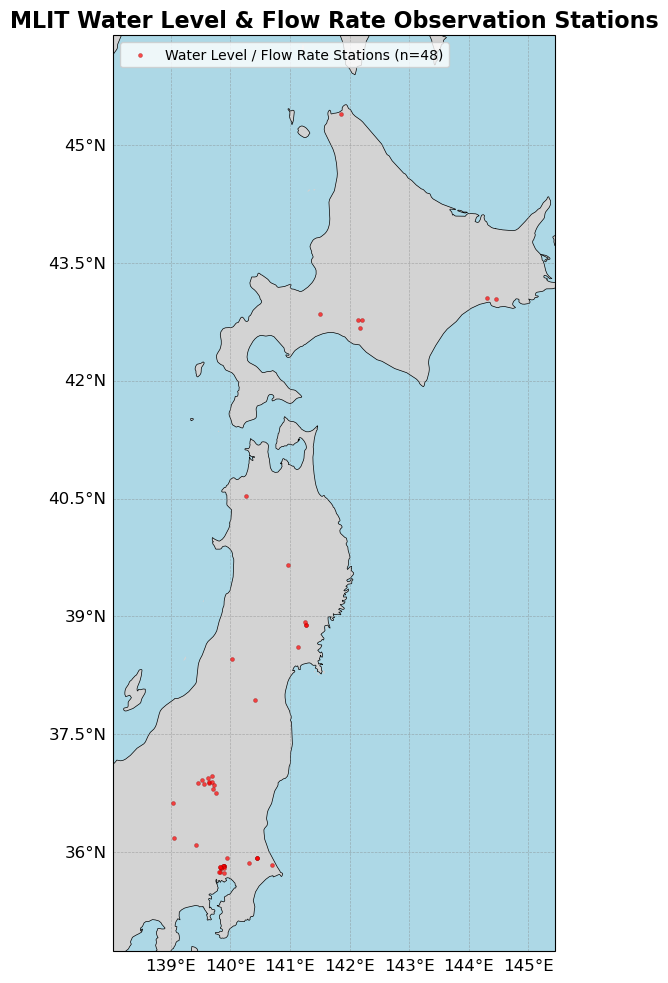

In [23]:
# Filter to stations with valid coordinates
df_valid = df_stations.dropna(subset=['latitude', 'longitude']).copy()

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(
    df_valid,
    geometry=gpd.points_from_xy(df_valid['longitude'], df_valid['latitude']),
    crs='EPSG:4326'
)

# --- Figure Setup ---
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Cartopy base layers
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND,
               zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black',
               zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# Gridlines
gl = ax.gridlines(draw_labels=True,
                  linestyle=MappingConfig.GRID_LINESTYLE,
                  color=MappingConfig.GRID_COLOR,
                  alpha=MappingConfig.GRID_ALPHA,
                  linewidth=MappingConfig.GRID_LINEWIDTH,
                  zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False

# Plot stations
gdf.plot(
    ax=ax,
    color='red',
    markersize=8,
    edgecolor='darkred',
    linewidth=0.3,
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_OBSERVATIONS,
    label=f'Water Level / Flow Rate Stations (n={len(gdf)})'
)

# Map extent — all of Japan
bounds = gdf.total_bounds  # [minx, miny, maxx, maxy]
ax.set_extent([bounds[0] - 1, bounds[2] + 1, bounds[1] - 1, bounds[3] + 1],
              crs=ccrs.PlateCarree())

ax.set_title('MLIT Water Level & Flow Rate Observation Stations', fontsize=16, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

## 7. Zoom: Seto Inland Sea Region

Zoom into the Seto Inland Sea area using the project's high-resolution boundary shapefile
to see which stations fall within the study region.

ValueError: aspect must be finite and positive 

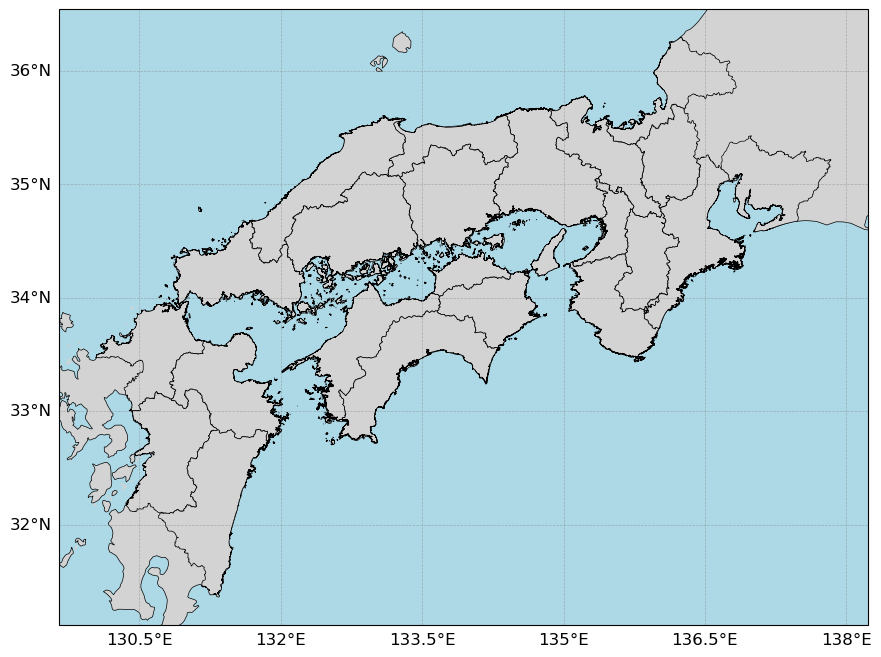

In [25]:
# Load high-resolution SIS boundary
target_region = MappingConfig.load_target_region()
land_boundary_file = MappingConfig.get_boundary_file(target_region)
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / land_boundary_file

fig, ax = plt.subplots(figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Cartopy base layers
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND,
               zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black',
               zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# High-resolution land boundary
if land_boundary_path.exists():
    sis_land = gpd.read_file(land_boundary_path)
    if sis_land.crs != 'EPSG:4326':
        sis_land = sis_land.to_crs('EPSG:4326')
    sis_land.plot(
        ax=ax,
        facecolor=MappingConfig.COLOR_LAND,
        edgecolor=MappingConfig.COLOR_LAND_EDGE,
        linewidth=MappingConfig.LINEWIDTH_LAND,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )

# Gridlines
gl = ax.gridlines(draw_labels=True,
                  linestyle=MappingConfig.GRID_LINESTYLE,
                  color=MappingConfig.GRID_COLOR,
                  alpha=MappingConfig.GRID_ALPHA,
                  linewidth=MappingConfig.GRID_LINEWIDTH,
                  zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False

# Filter stations to SIS approximate bounding box
sis_bounds = [130.5, 135.5, 33.0, 35.0]  # [lon_min, lon_max, lat_min, lat_max]
df_sis = df_valid[
    (df_valid['longitude'] >= sis_bounds[0]) & (df_valid['longitude'] <= sis_bounds[1]) &
    (df_valid['latitude'] >= sis_bounds[2]) & (df_valid['latitude'] <= sis_bounds[3])
].copy()

gdf_sis = gpd.GeoDataFrame(
    df_sis,
    geometry=gpd.points_from_xy(df_sis['longitude'], df_sis['latitude']),
    crs='EPSG:4326'
)

gdf_sis.plot(
    ax=ax,
    color='red',
    markersize=30,
    edgecolor='darkred',
    linewidth=0.5,
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_OBSERVATIONS,
    label=f'Stations in SIS region (n={len(gdf_sis)})'
)

ax.set_extent([sis_bounds[0] - 0.3, sis_bounds[1] + 0.3,
               sis_bounds[2] - 0.3, sis_bounds[3] + 0.3],
              crs=ccrs.PlateCarree())

ax.set_title(f'Water Level & Flow Rate Stations — {target_region} Region',
             fontsize=16, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

print(f'\nStations in the SIS bounding box: {len(df_sis)}')

## 8. Check Data Availability Period (Optional)

For a given station, the MLIT database provides a year-by-year availability matrix at:
```
/cgi-bin/SrchWaterData.exe?ID={station_id}&KIND=2&PAGE=0
```

The matrix uses image icons to indicate data presence:
- `ari.gif` or `ari0.gif` → Data **available** for that year.
- `nashi.gif` → No data.

The function below parses this matrix and returns a list of available years.

In [26]:
def get_available_years(driver, station_id):
    """
    Retrieve a list of years with available data for a specific station.
    
    Args:
        driver: Selenium WebDriver instance.
        station_id: The 15-digit station identifier.
    
    Returns:
        List of integers (years with data).
    """
    url = f'http://www1.river.go.jp/cgi-bin/SrchWaterData.exe?ID={station_id}&KIND=2&PAGE=0'
    driver.get(url)
    time.sleep(1.5)
    
    soup = BeautifulSoup(driver.page_source, 'html.parser')
    available_years = []
    
    for table in soup.find_all('table'):
        rows = table.find_all('tr')
        for row in rows:
            # Find the decade label cell (e.g., '193*', '200*')
            decade_cell = row.find('td', string=re.compile(r'\d{3}\*'))
            if decade_cell:
                decade_text = decade_cell.get_text(strip=True)
                decade = int(decade_text.replace('*', '0'))
                
                # Get the 10 year-columns after the decade label
                all_cells = row.find_all('td')
                decade_idx = all_cells.index(decade_cell)
                year_cells = all_cells[decade_idx + 1:]
                
                for offset, cell in enumerate(year_cells[:10]):
                    img = cell.find('img')
                    if img and 'ari' in img.get('src', ''):
                        available_years.append(decade + offset)
    
    return sorted(available_years)


# --- Example usage ---
# driver = create_driver()
# years = get_available_years(driver, '303051283310020')
# print(f'Available years: {years}')
# driver.quit()